In [12]:
pwd

'c:\\Users\\v.rajkumar\\AppData\\Local\\Programs\\Python\\Python37\\3 MONTH INTERNSHIP\\Ai2025\\Machine_Learning\\sentiment_Analysis'

In [25]:
from keras.preprocessing.text import Tokenizer
from keras.models import Sequential
from keras.layers import Embedding,LSTM,Dense
from keras.datasets import imdb
from keras.preprocessing.sequence import pad_sequences
from keras.callbacks import EarlyStopping,ModelCheckpoint
import matplotlib.pyplot as plt
import tensorflow as tf


# **important params**

In [14]:
vocab_size = 100000 # unique words
max_length = 100 # limit tokens as per sentence
 

# **train and test data**

In [15]:
(x_train,y_train),(x_test,y_test) = imdb.load_data()
x_train.shape

(25000,)

In [16]:
x_test.shape

(25000,)

# **preprocessing**

In [17]:
X_train = pad_sequences(sequences=x_train,maxlen=max_length,padding='pre',dtype='int32') # balancing sentence in same length vector
X_test = pad_sequences(sequences=x_test,maxlen=max_length,padding='pre',dtype='int32')

# **LSTM with embedding layer**

In [18]:
model = Sequential()
model.add(Embedding(input_dim = vocab_size,output_dim = 128,input_length = max_length))
model.add(LSTM(units = 128,activation = "relu"))
model.add(Dense(units=128,activation = 'relu'))
model.add(Dense(units = 1,activation = "sigmoid"))


# **optimiser,loss,metrics**

In [19]:
model.compile(optimizer='adam',metrics=['accuracy'],loss = "binary_crossentropy")
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_1 (Embedding)     (None, 100, 128)          12800000  
                                                                 
 lstm_1 (LSTM)               (None, 128)               131584    
                                                                 
 dense_2 (Dense)             (None, 128)               16512     
                                                                 
 dense_3 (Dense)             (None, 1)                 129       
                                                                 
Total params: 12,948,225
Trainable params: 12,948,225
Non-trainable params: 0
_________________________________________________________________


# **Call Backs**

In [20]:
early_stop = EarlyStopping(monitor='val_loss',patience=3,verbose=1)
model_ckp = ModelCheckpoint(filepath="model.h5",verbose=1,monitor='val_loss')

# **Train**

In [21]:
history = model.fit(epochs=10,x=X_train,y=y_train,callbacks=[model_ckp,early_stop],batch_size=64,validation_split=0.2)

Epoch 1/10


313/313 [==============================] - ETA: 0s - loss: 204222119936.0000 - accuracy: 0.6588
Epoch 1: saving model to model.h5
313/313 [==============================] - 85s 268ms/step - loss: 204222119936.0000 - accuracy: 0.6588 - val_loss: 0.5674 - val_accuracy: 0.7138
Epoch 2/10
313/313 [==============================] - ETA: 0s - loss: 975.4424 - accuracy: 0.7851
Epoch 2: saving model to model.h5
313/313 [==============================] - 82s 263ms/step - loss: 975.4424 - accuracy: 0.7851 - val_loss: 0.5409 - val_accuracy: 0.7272
Epoch 3/10
313/313 [==============================] - ETA: 0s - loss: 737085.1875 - accuracy: 0.8209
Epoch 3: saving model to model.h5
313/313 [==============================] - 87s 280ms/step - loss: 737085.1875 - accuracy: 0.8209 - val_loss: 0.5493 - val_accuracy: 0.7264
Epoch 4/10
313/313 [==============================] - ETA: 0s - loss: 0.3515 - accuracy: 0.8518
Epoch 4: saving model to model.h5
313/313 [==============================] - 84s 269ms/

# **Evaluate**

In [30]:
loss,accuracy = model.evaluate(X_test,y_test)
print("accuracy:",accuracy*100)
print("loss:",loss*100)

782/782 [==============================] - 18s 23ms/step - loss: 4136658.7500 - accuracy: 0.6922
accuracy: 69.22000050544739
loss: 413665875.0


# **Visualize**

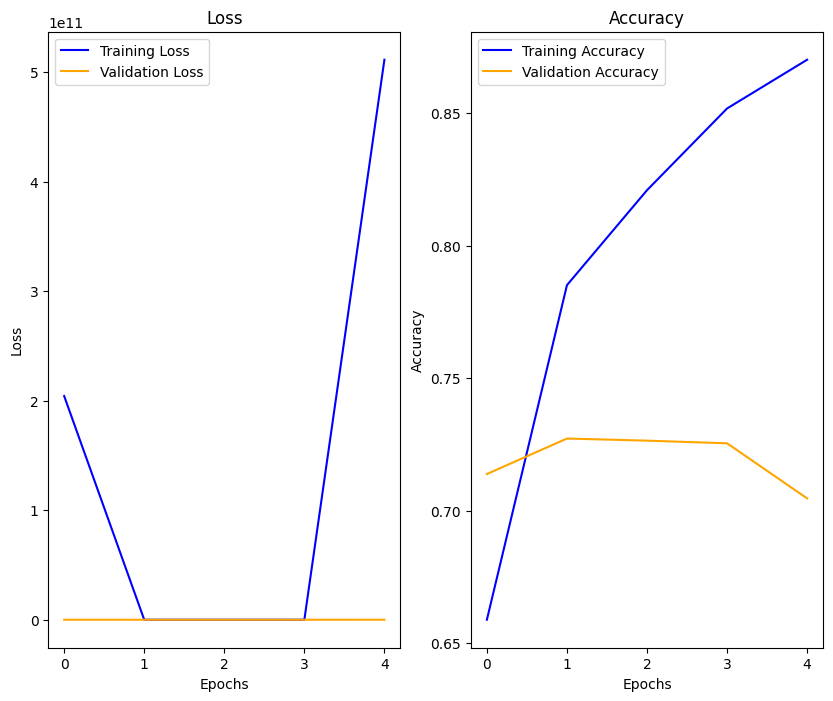

In [45]:
import matplotlib.pyplot as plt


fg, ax = plt.subplots(1, 2, figsize=(10, 8))

ax[0].plot(history.history['loss'], label='Training Loss', color='blue')
ax[0].plot(history.history['val_loss'], label='Validation Loss', color='orange')
ax[0].set_title('Loss')
ax[0].set_xlabel('Epochs')
ax[0].set_ylabel('Loss')
ax[0].legend()


ax[1].plot(history.history['accuracy'], label='Training Accuracy', color='blue')
ax[1].plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange')
ax[1].set_title('Accuracy')
ax[1].set_xlabel('Epochs')
ax[1].set_ylabel('Accuracy')
ax[1].legend()



# plt.tight_layout()
plt.show()




# **predict**

In [44]:
review = "The movie very bad"

tokenizer = Tokenizer(num_words=vocab_size)
sequence  = tokenizer.texts_to_sequences([review])
padded_sequence = pad_sequences(sequences=sequence,maxlen=max_length,padding='pre')

sentiment = model.predict(padded_sequence)
print(sentiment)

print("Sentiment:Positive" if sentiment > 0.5 else "Sentiment: Negative")

[[0.41280934]]
Sentiment: Negative
